# Fiscal policy in RANK and TANK

The model is the IKC model of the lecture: real rate rule ($r_t=r_{ss}$), real bonds and no markups ($\mu=1$).
The government follows the debt rule $dB_t=\rho_B\left(dB_{t-1}+dG_t\right)$ and taxes adjust, $T_t=\tau_tY_t$.
A share $\lambda$ of households is hand-to-mouth; `par.lam = 0` is RANK.
Unions set wages through the W-NKPC, and the central bank sets $1+i_t=(1+r_{ss})(1+\pi_{t+1})$.
The calibration is annual: $r_{ss}=0.02$, $G_{ss}=0.2$, $B_{ss}=0.25$.

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import RANKModel

## Settings

In [2]:
plt.rcParams.update({'axes.grid': True, 'grid.color': 'black', 'grid.alpha': 0.25, 'grid.linestyle': '--', 'font.size': 12})

## Steady state

In [3]:
model = RANKModel.RANKModelClass(name='RANK')
model.find_ss(do_print=True)
model.test_path()

 beta =   0.9804
 tau  =   0.2050
 C_R  =   0.8000, C_H =   0.7950
Discrepancy in Y =   0.00000000
Discrepancy in A =   0.00000000
shocks: G 
unknowns: Y C_R 

look at max(abs(path.VARNAME[:]-ss.VARNAME)):

 blocks.central_bank
  r                0.0e+00
 blocks.government
  B                0.0e+00
  taxes            0.0e+00
  tau              0.0e+00
  Z                0.0e+00
 blocks.households


  C_H              0.0e+00
  C                0.0e+00
  A_R              1.1e-16
  Euler            0.0e+00 [target]
 blocks.market_clearing
  clearing_Y       5.6e-17 [target]
  clearing_A       1.1e-16
 blocks.unions
  pi_w             0.0e+00
  pi               0.0e+00
 blocks.fisher
  i                1.7e-17


## Q1

Read the model equations in `blocks.py`. Check that they match the IKC model in RANK and TANK from the slides.

*Hint:* list the unknowns and targets in `RANKModel.py`, then write each block of `blocks.py` as an equation and compare with the "Simplified system of equations" slide.

- `central_bank`: real rate rule, $r_t=r_{ss}$.
- `government`: debt rule, budget $T_t=(1+r_{t-1})B_{t-1}+G_t-B_t$, tax rate $\tau_t=T_t/Y_t$ and post-tax income $Z_t=(1-\tau_t)Y_t=Y_t-T_t$.
- `households`: hand-to-mouth consume $C^H_t=Z_t$. Ricardian households satisfy the Euler equation and hold all the debt. Aggregate $C_t=\lambda C^H_t+(1-\lambda)C^R_t$.
- `market_clearing`: goods $Y_t=C_t+G_t$ is a target. By Walras' law, asset market clearing $(1-\lambda)A^R_t=B_t$ then holds automatically.
- `unions`: the W-NKPC, solved backwards from steady state, gives $\pi^w_t=\pi_t$ (the real wage is constant with $\mu=1$).
- `fisher`: the nominal rate implied by the real rate rule, $1+i_t=(1+r_{ss})(1+\pi_{t+1})$.
- Unknowns $\boldsymbol{Y},\boldsymbol{C}^R$, targets goods market and Euler.

## Q2

Solve for the IRF to a government spending shock in the RANK model using `model.find_IRFs()`. Compare the solution to the analytical formula derived in the slides.

*Hint:* in RANK, $\boldsymbol{M}^{RA}=(1-\beta)\boldsymbol{1}\boldsymbol{q}^{\prime}$ with $q_t=(1+r_{ss})^{-t}$, which you can build with `np.outer(np.ones(par.T),q)`. What is $\boldsymbol{M}^{RA}(d\boldsymbol{G}-d\boldsymbol{T})$? You can also solve the truncated IKC $(\boldsymbol{I}-\boldsymbol{M})d\boldsymbol{Y}=d\boldsymbol{G}-\boldsymbol{M}d\boldsymbol{T}$ with `np.linalg.solve(A,b)`.

In [4]:
model.compute_jacs()
model.find_IRFs(shocks=['G'])

par = model.par
ss = model.ss
dY = model.IRF['Y']
dG = model.IRF['G']
dT = model.IRF['taxes']

In RANK, $\boldsymbol{M}^{RA}=(1-\beta)\boldsymbol{1}\boldsymbol{q}^{\prime}$ and $\boldsymbol{q}^{\prime}(d\boldsymbol{G}-d\boldsymbol{T})=0$, so $\boldsymbol{M}^{RA}(d\boldsymbol{G}-d\boldsymbol{T})=\boldsymbol{0}$ and the IKC gives $d\boldsymbol{Y}=d\boldsymbol{G}$. We can also solve the truncated IKC $(\boldsymbol{I}-\boldsymbol{M})d\boldsymbol{Y}=d\boldsymbol{G}-\boldsymbol{M}d\boldsymbol{T}$ directly.

present value of the deficit: 2.4e-13
max |dY - analytical|: 0.0e+00
max |dY - dY_IKC|:     2.5e-13


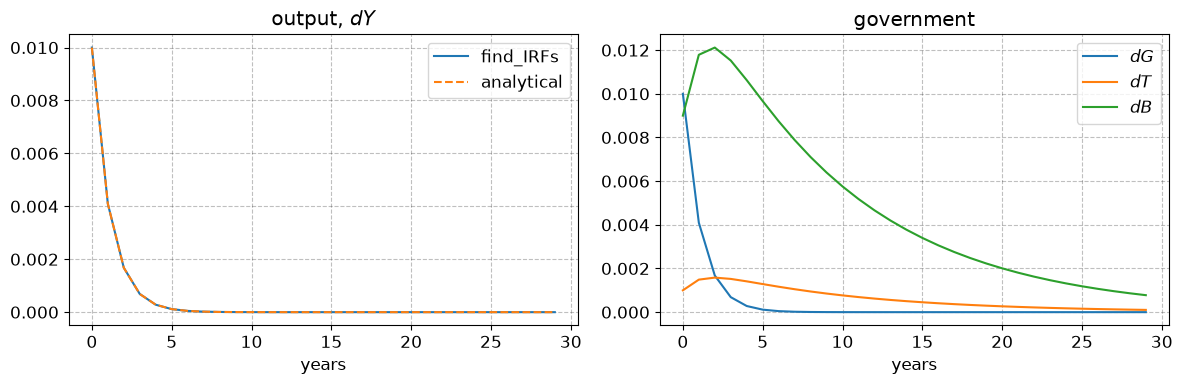

In [5]:
q = (1+ss.r)**(-np.arange(par.T))
dY_analytical = dG
M_RA = (1-par.beta)*np.outer(np.ones(par.T),q)
dY_IKC = np.linalg.solve(np.eye(par.T)-M_RA,dG-M_RA@dT)

print(f'present value of the deficit: {q@(dG-dT):.1e}')
print(f'max |dY - analytical|: {np.max(np.abs(dY-dY_analytical)):.1e}')
print(f'max |dY - dY_IKC|:     {np.max(np.abs(dY-dY_IKC)):.1e}')

fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(dY[:30],label='find_IRFs')
axes[0].plot(dY_analytical[:30],ls='--',label='analytical')
axes[0].set_title('output, $dY$')
axes[0].legend()
axes[1].plot(dG[:30],label='$dG$')
axes[1].plot(dT[:30],label='$dT$')
axes[1].plot(model.IRF['B'][:30],label='$dB$')
axes[1].set_title('government')
axes[1].legend()
for ax in axes: ax.set_xlabel('years')
fig.tight_layout()

## Q3

Compute the impact and cumulative multipliers in RANK, using your previous answer. What feature of the household block explains this result?

*Hint:* the impact multiplier is $dY_0/dG_0$ and the cumulative multiplier is $\boldsymbol{q}^{\prime}d\boldsymbol{Y}/\boldsymbol{q}^{\prime}d\boldsymbol{G}$ (use `q@dY`).

In [6]:
impact = dY[0]/dG[0]
cumulative = (q@dY)/(q@dG)
print(f'RANK: impact = {impact:.3f}, cumulative = {cumulative:.3f}')

RANK: impact = 1.000, cumulative = 1.000


Both multipliers are exactly 1, and consumption does not move.
The representative household consumes its permanent income, so its iMPCs are flat: $M_{t,s}=(1-\beta)\beta^s$.
The deficit has zero present value, so it does not change permanent income: a tax cut today is a tax rise later (Ricardian equivalence).
The result holds for any $\rho_B$; try `model.par.rho_B = 0.0` (balanced budget).

## Q4

Solve for the IRF to a government spending shock in the TANK model (`par.lam = 0.3`) using `model.find_IRFs()`. Compare the solution to the analytical formula derived in the slides.

*Hint:* make a copy with `model.copy()`, change `par.lam`, then solve the steady state, the Jacobians and the IRFs again. The analytical solution is on the "Solving TANK" slide.

max |dY - analytical|: 2.7e-14


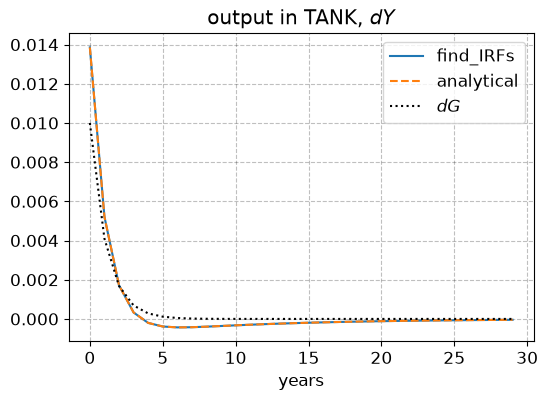

In [7]:
lam = 0.3

model_TANK = model.copy(name='TANK')
model_TANK.par.lam = lam
model_TANK.find_ss()
model_TANK.compute_jacs()
model_TANK.find_IRFs(shocks=['G'])

dY_TANK = model_TANK.IRF['Y']
dT_TANK = model_TANK.IRF['taxes']
dY_analytical = dG + lam/(1-lam)*(dG-dT_TANK)
print(f'max |dY - analytical|: {np.max(np.abs(dY_TANK-dY_analytical)):.1e}')

fig, ax = plt.subplots(figsize=(6,4))
ax.plot(dY_TANK[:30],label='find_IRFs')
ax.plot(dY_analytical[:30],ls='--',label='analytical')
ax.plot(dG[:30],ls=':',color='black',label='$dG$')
ax.set_title('output in TANK, $dY$')
ax.set_xlabel('years')
ax.legend();

## Q5

Compute the impact and cumulative multipliers in TANK. What feature of the household block explains this result?

*Hint:* what is $dT_0$ under the debt rule? Compare the impact multiplier with $1+\frac{\lambda}{1-\lambda}\rho_B$.

In [8]:
impact_TANK = dY_TANK[0]/dG[0]
cumulative_TANK = (q@dY_TANK)/(q@dG)
print(f'TANK: impact = {impact_TANK:.3f}, cumulative = {cumulative_TANK:.3f}')
print(f'formula for the impact: 1 + lam/(1-lam)*rho_B = {1+lam/(1-lam)*par.rho_B:.3f}')

TANK: impact = 1.386, cumulative = 1.000
formula for the impact: 1 + lam/(1-lam)*rho_B = 1.386


The impact multiplier is above 1: hand-to-mouth households spend all of the deficit at the date it arrives ($\boldsymbol{M}^{TA}=(1-\lambda)\boldsymbol{M}^{RA}+\lambda\boldsymbol{I}$).
With the debt rule, $dT_0=(1-\rho_B)dG_0$, so the impact multiplier is $1+\frac{\lambda}{1-\lambda}\rho_B$.
The cumulative multiplier is still 1: the boom while debt rises is offset by the bust when taxes repay it, because the deficit has zero present value. Ricardian consumption does not move.

## Q6

Compute the impact and cumulative multipliers for $\lambda \in \{0, 0.1, 0.2, 0.3, 0.4, 0.5\}$, and discuss your results.

*Hint:* reuse the steps of Q4 inside a loop.

lam = 0.0: impact = 1.000, cumulative = 1.000
lam = 0.1: impact = 1.100, cumulative = 1.000


lam = 0.2: impact = 1.225, cumulative = 1.000


lam = 0.3: impact = 1.386, cumulative = 1.000


lam = 0.4: impact = 1.600, cumulative = 1.000


lam = 0.5: impact = 1.900, cumulative = 1.000


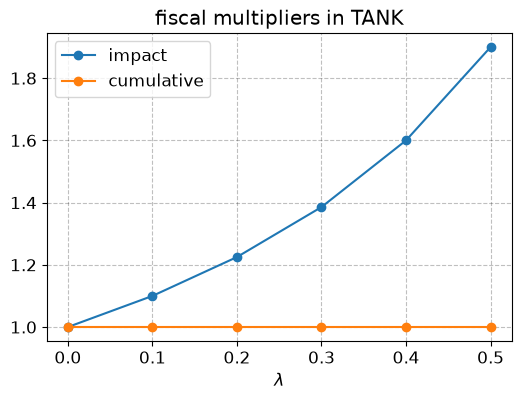

In [9]:
lams = [0.0,0.1,0.2,0.3,0.4,0.5]
impacts = []
cumulatives = []

for lam_ in lams:

    model_ = model.copy(name=f'lam={lam_}')
    model_.par.lam = lam_
    model_.find_ss()
    model_.compute_jacs()
    model_.find_IRFs(shocks=['G'])

    impacts.append(model_.IRF['Y'][0]/dG[0])
    cumulatives.append((q@model_.IRF['Y'])/(q@dG))
    print(f'lam = {lam_:.1f}: impact = {impacts[-1]:.3f}, cumulative = {cumulatives[-1]:.3f}')

fig, ax = plt.subplots(figsize=(6,4))
ax.plot(lams,impacts,marker='o',label='impact')
ax.plot(lams,cumulatives,marker='o',label='cumulative')
ax.set_xlabel('$\\lambda$')
ax.set_title('fiscal multipliers in TANK')
ax.legend();

The impact multiplier rises with $\lambda$, and faster and faster, like $\frac{1}{1-c_1}$ in IS-LM: more hand-to-mouth households spend more of the deficit, and their spending is someone else's income.
The cumulative multiplier stays at 1 for every $\lambda$: TANK changes the timing of output, not its present value. Getting a cumulative multiplier above 1 needs iMPCs that decline gradually, as in HANK.

## Q7

Compute the inflation response to the shock in RANK and TANK. Does inflation have any impact on the output response to the shock? Why?

*Hint:* inflation is `model.IRF['pi']`. To see whether inflation matters for output, change the slope of the W-NKPC, `par.kappa`, and check whether $d\boldsymbol{Y}$ moves.

RANK: max change in dY from raising kappa = 0.0e+00
TANK: max change in dY from raising kappa = 0.0e+00


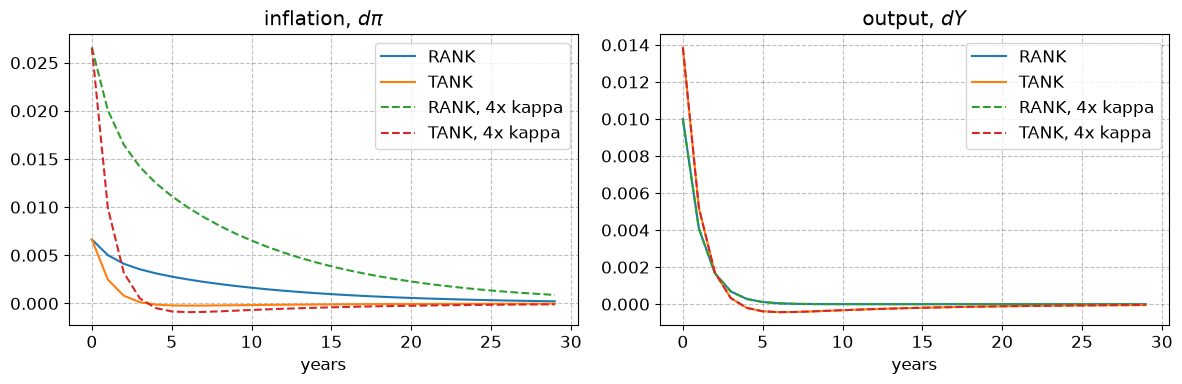

In [10]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(model.IRF['pi'][:30],label='RANK')
axes[0].plot(model_TANK.IRF['pi'][:30],label='TANK')
axes[0].set_title('inflation, $d\pi$')
axes[1].plot(model.IRF['Y'][:30],label='RANK')
axes[1].plot(model_TANK.IRF['Y'][:30],label='TANK')
axes[1].set_title('output, $dY$')

# same models with more flexible wages
for model_, label in [(model,'RANK'),(model_TANK,'TANK')]:
    model_flex = model_.copy(name=f'{label}, flexible wages')
    model_flex.par.kappa = 4*model_.par.kappa
    model_flex.compute_jacs()
    model_flex.find_IRFs(shocks=['G'])
    axes[0].plot(model_flex.IRF['pi'][:30],ls='--',label=f'{label}, 4x kappa')
    axes[1].plot(model_flex.IRF['Y'][:30],ls='--',label=f'{label}, 4x kappa')
    print(f'{label}: max change in dY from raising kappa = {np.max(np.abs(model_flex.IRF["Y"]-model_.IRF["Y"])):.1e}')

for ax in axes:
    ax.set_xlabel('years')
    ax.legend()
fig.tight_layout()

Inflation rises in both models: higher output means more hours, so unions push wages up, and with $\mu=1$ prices follow wages. It is more persistent in RANK, where output stays up as long as $G$ does.
But inflation has **no** effect on output: raising $\kappa$ changes inflation and leaves $d\boldsymbol{Y}$ exactly the same.
The reason is the three IKC assumptions. With the real rate rule, the central bank moves $i_t$ one for one with expected inflation, so $r_t=r_{ss}$. With real bonds, surprise inflation does not revalue debt. With $\mu=1$, there are no stocks and no capital gains. So households only see $\boldsymbol{Z}$, and the IKC pins down $d\boldsymbol{Y}$ alone.
In the DAG, `unions` and `fisher` come after the targets: inflation is computed from $\boldsymbol{Y}$, but nothing feeds back.
With a Taylor rule ($\phi>1$), higher inflation would raise $r_t$ and crowd out consumption; this is the generalized IKC at the end of the lecture.